In [1]:
"""
NOTEBOOK 2A.4 - Incongruity Heatmap (Komponen 4 NOVEL)
Fase 2A IndoMeme-XAI

Atribusi gambar via ICAM Stream 3 (complementary/incongruity stream).
Dua versi heatmap di-extract:
  - raw    : 1 - |cos(text, image)|  per patch
  - softmax: softmax(incongruity)    -> bobot yg model pakai (faithful)

Output dipakai utk:
  - Visualisasi case study (Fase 2C)
  - ROAR masking di gambar (Fase 2B)
"""

from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input/datasets/reynaldaryansyah")
ROOT_DIR     = KAGGLE_INPUT / "xai-dataset" / "data" / "data"
CSV_PATH     = ROOT_DIR / "processed" / "all_splits.csv"
IMG_DIR      = ROOT_DIR / "images"
CKPT_PATH    = Path("/kaggle/input/datasets/reynaldaryansyah/xai-dataset/exp-1b9-ensemble/model_seed7.pt")  # sesuaikan

OUTPUT_DIR = Path("/kaggle/working/xai_2A4_incongruity_heatmap")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    exp_id           = "2A.4_incongruity_heatmap",
    seed             = 42,

    text_model_name  = "indolem/indobertweet-base-uncased",
    image_model_name = "google/vit-base-patch16-224-in21k",
    freeze_n_layers  = 4,
    topic_emb_dim    = 32,
    head_hidden      = 256,
    dropout          = 0.3,
    icam_num_heads   = 8,
    icam_dropout     = 0.1,
    supcon_proj_hidden  = 128,
    supcon_proj_out     = 128,
    max_seq_len      = 128,

    batch_size       = 16,
    n_viz_samples    = 8,
    grid_size        = 14,
    img_size         = 224,
)

print(f"Experiment: {CONFIG['exp_id']}")
print(f"Checkpoint: {CKPT_PATH}")

Experiment: 2A.4_incongruity_heatmap
Checkpoint: /kaggle/input/datasets/reynaldaryansyah/xai-dataset/exp-1b9-ensemble/model_seed7.pt


In [2]:
import os, json, random, time, math, re, unicodedata
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from torchvision import transforms
from transformers import AutoTokenizer, AutoModel, ViTImageProcessor, ViTModel
from tqdm.auto import tqdm

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


In [3]:
SLANG_DICT = {
    "gw":"saya","gue":"saya","gua":"saya","guwe":"saya",
    "lu":"kamu","lo":"kamu","loe":"kamu","elo":"kamu","elu":"kamu",
    "ane":"saya","ente":"kamu","agan":"kamu","sis":"kakak",
    "bro":"kawan","bray":"kawan","bre":"kawan","cuy":"kawan",
    "klian":"kalian","kmu":"kamu","kamuh":"kamu",
    "aq":"aku","akoh":"aku","akuh":"aku",
    "gak":"tidak","ga":"tidak","gk":"tidak","nggak":"tidak",
    "ngga":"tidak","ngk":"tidak","kgk":"tidak","tdk":"tidak",
    "engga":"tidak","enggak":"tidak","kga":"tidak",
    "yg":"yang","dgn":"dengan","dg":"dengan","krn":"karena",
    "krna":"karena","utk":"untuk","tp":"tapi","tpi":"tapi",
    "klo":"kalau","klau":"kalau","kl":"kalau","klu":"kalau",
    "spy":"supaya","ato":"atau",
    "bgt":"banget","bgtt":"banget","bngt":"banget",
    "bnr":"benar","bener":"benar",
    "emg":"memang","emang":"memang","mmg":"memang",
    "skrg":"sekarang","skrng":"sekarang",
    "td":"tadi","tdi":"tadi","bsk":"besok",
    "knp":"kenapa","gmn":"bagaimana","gimana":"bagaimana",
    "gmana":"bagaimana","kyk":"seperti","kayak":"seperti","kek":"seperti",
    "udh":"sudah","udah":"sudah","uda":"sudah","dah":"sudah",
    "blm":"belum","blom":"belum",
    "lg":"lagi","lgi":"lagi","msh":"masih","msi":"masih",
    "jd":"jadi","jdi":"jadi",
    "tau":"tahu","taw":"tahu","tw":"tahu",
    "liat":"lihat","ngeliat":"melihat","denger":"dengar",
    "ngomong":"bicara","blng":"bilang","bilg":"bilang",
    "aja":"saja","doang":"saja","doank":"saja",
    "sih":"","deh":"","dong":"","kok":"","lah":"",
    "loh":"","lho":"","yah":"",
    "iy":"iya","iyaa":"iya","iye":"iya","yup":"iya","yoi":"iya",
    "org":"orang","orng":"orang","orgnya":"orangnya",
    "dr":"dari","dri":"dari","kpd":"kepada",
    "thd":"terhadap","ttg":"tentang",
    "abis":"habis","trs":"terus","trus":"terus",
    "tmn":"teman","temen":"teman","tman":"teman",
    "rmh":"rumah","kntr":"kantor","krj":"kerja",
    "ank":"anak","indo":"indonesia",
    "cwo":"cowok","cwe":"cewek","cwok":"cowok","cwek":"cewek",
    "wkwk":"haha","wkwkwk":"haha","wkwkwkwk":"haha","wkwkwkwkwk":"haha",
    "hahaha":"haha","hahahaha":"haha",
    "hehehe":"hehe","hehehehe":"hehe",
    "anjir":"anjing","anjay":"anjing","anjrit":"anjing",
    "anjr":"anjing","anying":"anjing","njir":"anjing",
    "bgsd":"bangsat","bgst":"bangsat",
    "bjir":"anjing","bjg":"bajingan",
    "kntl":"kontol","mmk":"memek","tai":"tahi",
}

In [4]:
URL_PATTERN     = re.compile(r"(https?://\S+|www\.\S+|\S+\.(?:com|co\.id|net|org|id|tv|me)\b\S*)", re.IGNORECASE)
MENTION_PATTERN = re.compile(r"@\w+")
HASHTAG_PATTERN = re.compile(r"#(\w+)")
ALLOWED_PUNCT   = re.compile(r"[^\w\s\.,!?\-'\"]+", re.UNICODE)
MULTI_SPACE     = re.compile(r"\s+")

def _normalize_unicode(t): return unicodedata.normalize("NFKC", t)
def _normalize_slang(text, slang_dict=SLANG_DICT):
    out = []
    for tok in text.split():
        prefix, suffix, core = "", "", tok
        while core and not core[0].isalnum(): prefix += core[0]; core = core[1:]
        while core and not core[-1].isalnum(): suffix = core[-1] + suffix; core = core[:-1]
        out.append(f"{prefix}{slang_dict.get(core.lower(), core)}{suffix}")
    return " ".join(out)

def clean_ocr(text):
    if text is None: return ""
    if isinstance(text, float) and pd.isna(text): return ""
    text = _normalize_unicode(str(text)).lower()
    text = URL_PATTERN.sub(" ", text); text = MENTION_PATTERN.sub(" ", text)
    text = HASHTAG_PATTERN.sub(r"\1", text); text = ALLOWED_PUNCT.sub(" ", text)
    text = _normalize_slang(text)
    return MULTI_SPACE.sub(" ", text).strip()

SEP_TOKEN = "[SEP]"
def _safe_str(x):
    if x is None: return ""
    if isinstance(x, float) and pd.isna(x): return ""
    return str(x).strip()
def format_input(topic, caption, ocr_cleaned, sep=SEP_TOKEN):
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        topic_str = "unknown"
    elif isinstance(topic, (list, tuple, set)):
        items = sorted({str(t).lower().strip() for t in topic if t})
        topic_str = ",".join(items) if items else "unknown"
    else:
        topic_str = str(topic).lower().strip() or "unknown"
    return f"[{topic_str}] {_safe_str(caption)} {sep} {_safe_str(ocr_cleaned)}".strip()

In [5]:
df = pd.read_csv(CSV_PATH)
LABEL_MAP = {"not hate": 0, "hate": 1}
df["label"] = df["hate_final"].map(LABEL_MAP)
df["ocr_cleaned"] = df["ocr"].apply(clean_ocr)
df["text_input"]  = df.apply(lambda r: format_input(r["topic"], r["caption"], r["ocr_cleaned"]), axis=1)

def resolve_image_path(row):
    raw = row.get("local_image_path") or row.get("image_path")
    if raw is None or (isinstance(raw, float) and pd.isna(raw)): return None
    fname = Path(str(raw).replace("\\","/")).name
    return str(IMG_DIR / row["split"] / fname)
df["full_image_path"] = df.apply(resolve_image_path, axis=1)

TOPIC_LIST = ["political","national origin","individual","institutions",
              "gender","religion","social sub-groups","unknown"]
TOPIC2IDX = {t: i for i, t in enumerate(TOPIC_LIST)}
N_TOPICS  = len(TOPIC_LIST)

def topic_to_multihot(topic):
    vec = np.zeros(N_TOPICS, dtype=np.float32)
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        vec[TOPIC2IDX["unknown"]] = 1.0; return vec
    parts = [p.strip().lower() for p in str(topic).split(",") if p.strip()]
    found = False
    for p in parts:
        if p in TOPIC2IDX: vec[TOPIC2IDX[p]] = 1.0; found = True
    if not found: vec[TOPIC2IDX["unknown"]] = 1.0
    return vec

df["topic_multihot"] = df["topic"].apply(topic_to_multihot)
df_test = df[df["split"] == "test"].copy().reset_index(drop=True)
print(f"Test samples: {len(df_test)}")

Test samples: 1005


In [6]:
tokenizer       = AutoTokenizer.from_pretrained(CONFIG["text_model_name"])
image_processor = ViTImageProcessor.from_pretrained(CONFIG["image_model_name"])
IMG_MEAN = image_processor.image_mean
IMG_STD  = image_processor.image_std

EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

In [7]:
class IndoMemeDataset(Dataset):
    def __init__(self, df_split, tokenizer, transform, max_seq_len=128):
        self.df = df_split.reset_index(drop=True)
        self.tokenizer = tokenizer; self.transform = transform; self.max_seq_len = max_seq_len

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["full_image_path"]).convert("RGB")
        img_tensor = self.transform(img)
        enc = self.tokenizer(row["text_input"], padding="max_length", truncation=True,
                             max_length=self.max_seq_len, return_tensors="pt")
        return {
            "input_ids":      enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "pixel_values":   img_tensor,
            "topic":          torch.from_numpy(row["topic_multihot"]),
            "label":          torch.tensor(int(row["label"]), dtype=torch.long),
            "idx":            int(row["idx"]),
            "image_path":     row["full_image_path"],
        }

ds_test = IndoMemeDataset(df_test, tokenizer, EVAL_TRANSFORM, CONFIG["max_seq_len"])
dl_test = DataLoader(ds_test, batch_size=CONFIG["batch_size"], shuffle=False,
                     num_workers=2, pin_memory=True)
print(f"Loader: {len(dl_test)} batches")

Loader: 63 batches


In [8]:
class ICAMFusion(nn.Module):
    def __init__(self, hidden_dim=768, num_heads=8, dropout=0.1):
        super().__init__()
        self.t2i_attn = nn.MultiheadAttention(hidden_dim, num_heads, dropout=dropout, batch_first=True)
        self.i2t_attn = nn.MultiheadAttention(hidden_dim, num_heads, dropout=dropout, batch_first=True)
        self.gate_relevant    = nn.Linear(2 * hidden_dim, hidden_dim)
        self.gate_incongruent = nn.Linear(2 * hidden_dim, hidden_dim)
        self.fusion_proj = nn.Linear(hidden_dim, hidden_dim)
        self.layer_norm  = nn.LayerNorm(hidden_dim)

        self.save_attn        = False
        self.last_t2i_attn    = None
        self.last_i2t_attn    = None
        self.last_incongruity = None
        self.last_g1          = None
        self.last_g2          = None

    def forward(self, text_h, image_h, text_mask=None):
        text_kpm = (~text_mask.bool()) if text_mask is not None else None

        t2i_out, t2i_w = self.t2i_attn(text_h, image_h, image_h, key_padding_mask=None,
                                        need_weights=self.save_attn, average_attn_weights=True)
        i2t_out, i2t_w = self.i2t_attn(image_h, text_h, text_h, key_padding_mask=text_kpm,
                                        need_weights=self.save_attn, average_attn_weights=True)
        h_image_pooled = i2t_out.mean(dim=1)

        text_norm  = F.normalize(text_h,  dim=-1)
        image_norm = F.normalize(image_h, dim=-1)
        sim         = torch.bmm(text_norm, image_norm.transpose(1, 2))
        incongruity = 1.0 - sim.abs()
        inc_w       = F.softmax(incongruity, dim=-1)
        h_inc       = torch.bmm(inc_w, image_h)

        if text_mask is not None:
            m = text_mask.unsqueeze(-1).float()
            h_inc_pooled = (h_inc * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
        else:
            h_inc_pooled = h_inc.mean(dim=1)

        h_text = text_h[:, 0]
        g1 = torch.sigmoid(self.gate_relevant(   torch.cat([h_text, h_image_pooled], dim=-1)))
        g2 = torch.sigmoid(self.gate_incongruent(torch.cat([h_text, h_inc_pooled  ], dim=-1)))
        fused   = h_text + g1 * h_image_pooled + g2 * h_inc_pooled
        h_fused = self.layer_norm(self.fusion_proj(fused))

        if self.save_attn:
            self.last_t2i_attn    = t2i_w.detach() if t2i_w is not None else None
            self.last_i2t_attn    = i2t_w.detach() if i2t_w is not None else None
            self.last_incongruity = incongruity.detach()
            self.last_g1          = g1.detach()
            self.last_g2          = g2.detach()

        return h_fused, g1.mean().item(), g2.mean().item()

In [9]:
class ICAMHateModelSupCon(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.text_encoder  = AutoModel.from_pretrained(cfg["text_model_name"])
        self.image_encoder = ViTModel.from_pretrained(cfg["image_model_name"])
        for p in self.text_encoder.parameters():  p.requires_grad = False
        for p in self.image_encoder.parameters(): p.requires_grad = False

        hidden = self.text_encoder.config.hidden_size
        self.icam = ICAMFusion(hidden_dim=hidden, num_heads=cfg["icam_num_heads"], dropout=cfg["icam_dropout"])
        self.supcon_proj = nn.Sequential(
            nn.Linear(hidden, cfg["supcon_proj_hidden"]),
            nn.ReLU(),
            nn.Linear(cfg["supcon_proj_hidden"], cfg["supcon_proj_out"]),
        )
        self.topic_proj = nn.Sequential(nn.Linear(N_TOPICS, cfg["topic_emb_dim"]), nn.GELU())
        head_in = hidden + cfg["topic_emb_dim"]
        self.head = nn.Sequential(
            nn.Linear(head_in, cfg["head_hidden"]), nn.GELU(),
            nn.Dropout(cfg["dropout"]),
            nn.Linear(cfg["head_hidden"], 2),
        )

    def forward(self, input_ids, attention_mask, pixel_values, topic):
        t_out = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        i_out = self.image_encoder(pixel_values=pixel_values)
        h_fused, g1m, g2m = self.icam(t_out.last_hidden_state, i_out.last_hidden_state, attention_mask)
        supcon_features = F.normalize(self.supcon_proj(h_fused), dim=-1)
        topic_emb = self.topic_proj(topic)
        logits    = self.head(torch.cat([h_fused, topic_emb], dim=-1))
        return logits, supcon_features, g1m, g2m

In [10]:
model = ICAMHateModelSupCon(CONFIG).to(DEVICE)
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
state = ckpt["state_dict"] if (isinstance(ckpt, dict) and "state_dict" in ckpt) else ckpt
missing, unexpected = model.load_state_dict(state, strict=False)
print(f"Loaded checkpoint. Missing={len(missing)}, Unexpected={len(unexpected)}")

for p in model.parameters(): p.requires_grad = False
model.eval()
model.icam.save_attn = True   # AKTIFKAN penyimpanan incongruity
print(f"save_attn = {model.icam.save_attn}")

pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loaded checkpoint. Missing=0, Unexpected=0
save_attn = True


In [11]:
@torch.no_grad()
def extract_incongruity_batch(model, batch):
    """
    Extract Incongruity Heatmap dari ICAM Stream 3.

    Pipeline:
      1. Forward pass -> model.icam.last_incongruity ter-update [B, T, P]
         dimana incongruity[i,j] = 1 - |cos(text_h[i], image_h[j])|.
      2. Hitung dua versi heatmap:
         - raw     : incongruity itu sendiri (magnitude misalignment)
         - softmax : F.softmax(incongruity) -> bobot persis yg model pakai
      3. Average atas T_text dgn mask, drop CLS image patch (posisi 0).
      4. Reshape ke 14x14.

    Returns:
      raw_maps     : np.ndarray [B, 14, 14]
      softmax_maps : np.ndarray [B, 14, 14]   <-- primary (faithful)
      preds, probs : np.ndarray [B]
    """
    input_ids      = batch["input_ids"].to(DEVICE)
    attention_mask = batch["attention_mask"].to(DEVICE)
    pixel_values   = batch["pixel_values"].to(DEVICE)
    topic          = batch["topic"].to(DEVICE)

    with autocast(device_type="cuda"):
        logits, _, _, _ = model(input_ids, attention_mask, pixel_values, topic)

    # Raw incongruity [B, T, P]
    raw = model.icam.last_incongruity.float()

    # Softmax (yang model pakai) [B, T, P]
    softmax_w = F.softmax(raw, dim=-1)

    # Average atas T dgn attention mask
    mask_f = attention_mask.float().unsqueeze(-1)                          # [B, T, 1]
    raw_avg = (raw       * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1.0)
    sm_avg  = (softmax_w * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1.0)

    # Drop CLS image (pos 0)
    raw_p = raw_avg[:, 1:]                                                  # [B, 196]
    sm_p  = sm_avg[:, 1:]

    G = CONFIG["grid_size"]
    raw_maps = raw_p.reshape(-1, G, G)
    sm_maps  = sm_p.reshape(-1, G, G)

    probs = F.softmax(logits.float(), dim=-1)
    preds = probs.argmax(dim=-1)
    pred_probs = probs.gather(1, preds.unsqueeze(1)).squeeze(1)

    return (raw_maps.cpu().numpy(),
            sm_maps.cpu().numpy(),
            preds.cpu().numpy(),
            pred_probs.cpu().numpy())

In [12]:
all_raw, all_sm, all_preds, all_probs = [], [], [], []
all_labels, all_idxs, all_paths = [], [], []

t0 = time.time()
for batch in tqdm(dl_test, desc="incongruity extraction"):
    raw_b, sm_b, preds_b, probs_b = extract_incongruity_batch(model, batch)
    all_raw.append(raw_b)
    all_sm.append(sm_b)
    all_preds.append(preds_b)
    all_probs.append(probs_b)
    all_labels.extend(batch["label"].tolist())
    all_idxs.extend(batch["idx"].tolist())
    all_paths.extend(batch["image_path"])

all_raw    = np.concatenate(all_raw,   axis=0)
all_sm     = np.concatenate(all_sm,    axis=0)
all_preds  = np.concatenate(all_preds, axis=0)
all_probs  = np.concatenate(all_probs, axis=0)
all_labels = np.array(all_labels, dtype=np.int8)
all_idxs   = np.array(all_idxs,   dtype=np.int64)

elapsed = time.time() - t0
print(f"\nDone. {len(all_raw)} samples in {elapsed/60:.1f} min")
print(f"Raw map shape: {all_raw.shape}")
print(f"Softmax map shape: {all_sm.shape}")

incongruity extraction:   0%|          | 0/63 [00:00<?, ?it/s]


Done. 1005 samples in 0.2 min
Raw map shape: (1005, 14, 14)
Softmax map shape: (1005, 14, 14)


In [13]:
np.savez_compressed(
    OUTPUT_DIR / "incongruity_maps.npz",
    maps_raw_14x14=all_raw.astype(np.float32),
    maps_softmax_14x14=all_sm.astype(np.float32),
    pred_class=all_preds.astype(np.int8),
    pred_prob=all_probs.astype(np.float32),
    true_label=all_labels,
    idxs=all_idxs,
)
with open(OUTPUT_DIR / "image_paths.json", "w") as f:
    json.dump([{"idx": int(i), "path": p} for i, p in zip(all_idxs, all_paths)], f)
print(f"Saved: incongruity_maps.npz  ({(all_raw.nbytes + all_sm.nbytes)/1e6:.2f} MB)")

Saved: incongruity_maps.npz  (1.58 MB)


In [14]:
print(f"\n{'='*72}\nINCONGRUITY HEATMAP SANITY CHECKS\n{'='*72}")
acc = (all_preds == all_labels).mean()
print(f"Test accuracy : {acc:.4f}  (harus ~0.815)")

def report_map(name, maps):
    flat = maps.reshape(len(maps), -1)
    flat_sorted = -np.sort(-flat, axis=1)
    top10 = flat_sorted[:, :10].sum(axis=1)
    top20 = flat_sorted[:, :20].sum(axis=1)
    print(f"\n[{name}]")
    print(f"  Mean / Std       : {maps.mean():.5f} / {maps.std():.5f}")
    print(f"  Min / Max        : {maps.min():.5f} / {maps.max():.5f}")
    print(f"  Max / Mean ratio : {maps.max() / maps.mean():.2f}x")
    print(f"  Top-10 share     : {top10.mean()*100:.1f}%  (uniform={10/196*100:.1f}%, ratio={top10.mean()*196/10:.2f}x)")
    print(f"  Top-20 share     : {top20.mean()*100:.1f}%  (uniform={20/196*100:.1f}%, ratio={top20.mean()*196/20:.2f}x)")

    # Per-class differentiation
    for cls, cname in [(0, "not_hate"), (1, "hate")]:
        sel = (all_preds == cls)
        if sel.sum() > 0:
            sub_top10 = -np.sort(-flat[sel], axis=1)[:, :10].sum(axis=1)
            print(f"    Pred={cname} (n={sel.sum()}): top10_share={sub_top10.mean()*100:.1f}%  max={maps[sel].max():.4f}")

report_map("RAW incongruity", all_raw)
report_map("SOFTMAX incongruity (faithful, model usage)", all_sm)

print(f"\n{'='*72}\nKOMPARASI SELECTIVITY DI 3 KOMPONEN GAMBAR\n{'='*72}")
print(f"  2A.2 Cross-Attention (T2I) : top-10 ~ 5.2%  (1.02x uniform)")
print(f"  2A.3 ViT Rollout           : top-10 ~ 6.9%  (1.35x uniform)")
flat_sm = all_sm.reshape(len(all_sm), -1)
sm_top10 = -np.sort(-flat_sm, axis=1)[:, :10].sum(axis=1)
print(f"  2A.4 Incongruity Softmax    : top-10 = {sm_top10.mean()*100:.1f}%  ({sm_top10.mean()*196/10:.2f}x uniform)  <-- KOMPONEN 4 NOVEL")


INCONGRUITY HEATMAP SANITY CHECKS
Test accuracy : 0.8149  (harus ~0.815)

[RAW incongruity]
  Mean / Std       : 0.96837 / 0.01055
  Min / Max        : 0.89029 / 0.99032
  Max / Mean ratio : 1.02x
  Top-10 share     : 978.6%  (uniform=5.1%, ratio=191.82x)
  Top-20 share     : 1955.1%  (uniform=10.2%, ratio=191.60x)
    Pred=not_hate (n=648): top10_share=978.6%  max=0.9903
    Pred=hate (n=357): top10_share=978.7%  max=0.9867

[SOFTMAX incongruity (faithful, model usage)]
  Mean / Std       : 0.00508 / 0.00003
  Min / Max        : 0.00481 / 0.00529
  Max / Mean ratio : 1.04x
  Top-10 share     : 5.1%  (uniform=5.1%, ratio=1.01x)
  Top-20 share     : 10.2%  (uniform=10.2%, ratio=1.00x)
    Pred=not_hate (n=648): top10_share=5.1%  max=0.0053
    Pred=hate (n=357): top10_share=5.1%  max=0.0053

KOMPARASI SELECTIVITY DI 3 KOMPONEN GAMBAR
  2A.2 Cross-Attention (T2I) : top-10 ~ 5.2%  (1.02x uniform)
  2A.3 ViT Rollout           : top-10 ~ 6.9%  (1.35x uniform)
  2A.4 Incongruity Softmax    

In [15]:
def overlay_attention(img_pil, attn_14x14, alpha=0.5, cmap_name="jet"):
    H, W = CONFIG["img_size"], CONFIG["img_size"]
    attn_t = torch.from_numpy(attn_14x14).float().unsqueeze(0).unsqueeze(0)
    attn_up = F.interpolate(attn_t, size=(H, W), mode="bilinear", align_corners=False)
    attn_np = attn_up.squeeze().numpy()
    a_min, a_max = attn_np.min(), attn_np.max()
    attn_norm = (attn_np - a_min) / (a_max - a_min + 1e-8)
    cmap = cm.get_cmap(cmap_name)
    heat = cmap(attn_norm)[..., :3]
    img_resized = img_pil.resize((W, H))
    img_arr = np.asarray(img_resized).astype(np.float32) / 255.0
    if img_arr.ndim == 2: img_arr = np.stack([img_arr]*3, axis=-1)
    if img_arr.shape[-1] == 4: img_arr = img_arr[..., :3]
    blended = (1 - alpha) * img_arr + alpha * heat
    return np.clip(blended, 0, 1)

/tmp/ipykernel_22/3675462437.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


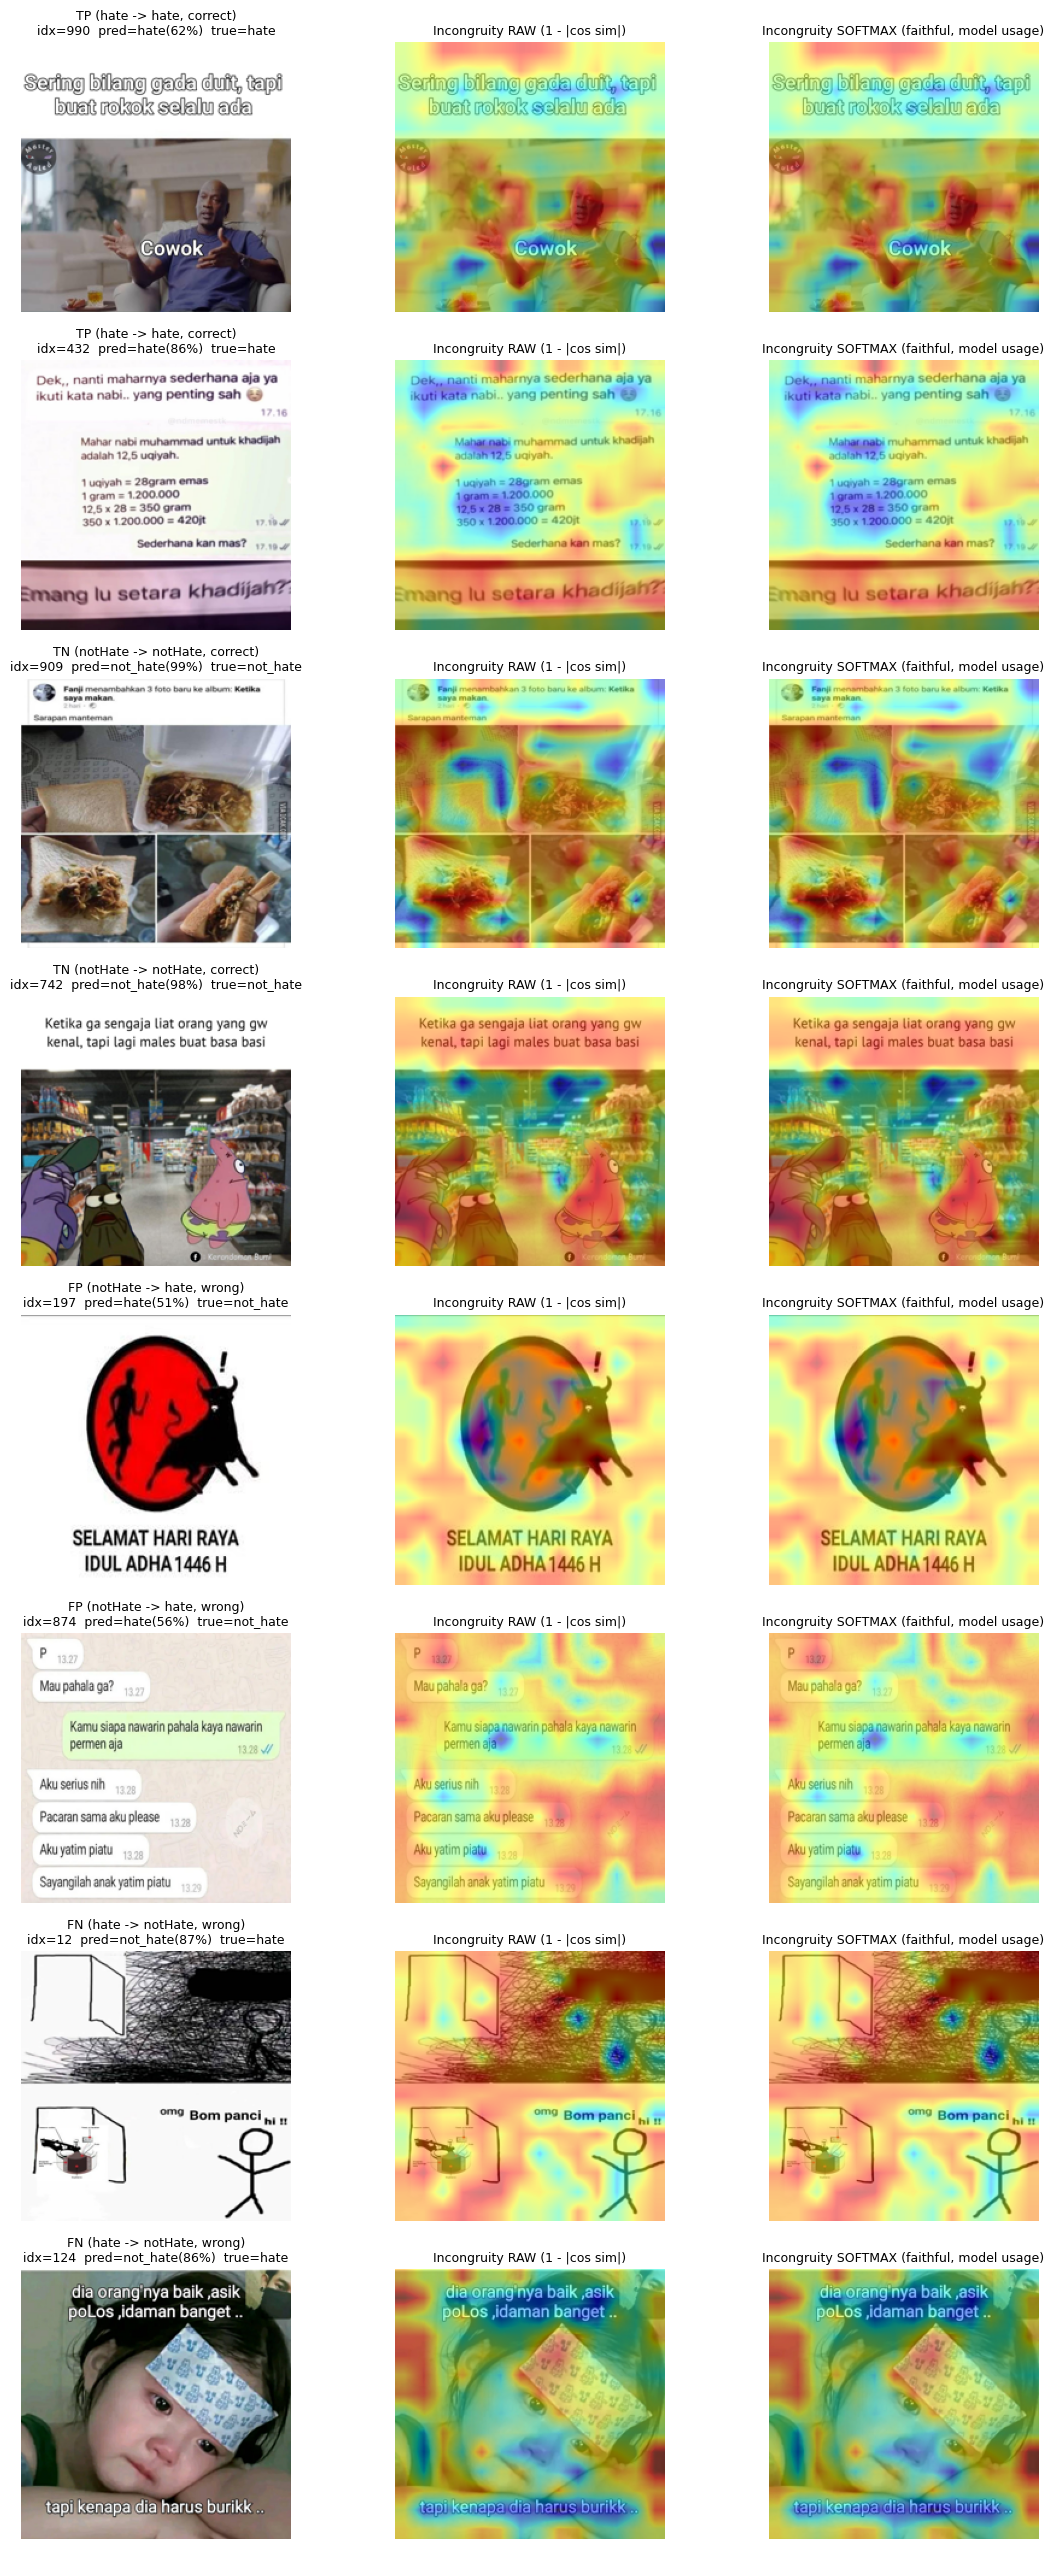


Saved: /kaggle/working/xai_2A4_incongruity_heatmap/incongruity_visualizations.png


In [16]:
mask_tp = (all_preds == 1) & (all_labels == 1)
mask_tn = (all_preds == 0) & (all_labels == 0)
mask_fp = (all_preds == 1) & (all_labels == 0)
mask_fn = (all_preds == 0) & (all_labels == 1)

def pick_indices(mask, k, seed=0):
    pool = np.where(mask)[0]
    return np.random.RandomState(seed).choice(pool, size=min(k, len(pool)), replace=False)

picks = {
    "TP (hate -> hate, correct)":         pick_indices(mask_tp, 2),
    "TN (notHate -> notHate, correct)":   pick_indices(mask_tn, 2),
    "FP (notHate -> hate, wrong)":        pick_indices(mask_fp, 2),
    "FN (hate -> notHate, wrong)":        pick_indices(mask_fn, 2),
}

n_total = sum(len(v) for v in picks.values())
fig, axes = plt.subplots(n_total, 3, figsize=(12, 3.2*n_total))
if n_total == 1: axes = axes.reshape(1, 3)

row = 0
for cat, idx_list in picks.items():
    for i in idx_list:
        idx_global = int(all_idxs[i])
        img_path   = all_paths[i]
        pred_str   = "hate" if all_preds[i] == 1 else "not_hate"
        true_str   = "hate" if all_labels[i] == 1 else "not_hate"
        prob_pct   = all_probs[i] * 100

        img_pil = Image.open(img_path).convert("RGB")
        blend_raw = overlay_attention(img_pil, all_raw[i], alpha=0.5)
        blend_sm  = overlay_attention(img_pil, all_sm[i],  alpha=0.5)

        axes[row, 0].imshow(img_pil.resize((CONFIG["img_size"], CONFIG["img_size"])))
        axes[row, 0].set_title(f"{cat}\nidx={idx_global}  pred={pred_str}({prob_pct:.0f}%)  true={true_str}", fontsize=9)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(blend_raw)
        axes[row, 1].set_title("Incongruity RAW (1 - |cos sim|)", fontsize=9)
        axes[row, 1].axis("off")

        axes[row, 2].imshow(blend_sm)
        axes[row, 2].set_title("Incongruity SOFTMAX (faithful, model usage)", fontsize=9)
        axes[row, 2].axis("off")
        row += 1

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "incongruity_visualizations.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"\nSaved: {OUTPUT_DIR / 'incongruity_visualizations.png'}")

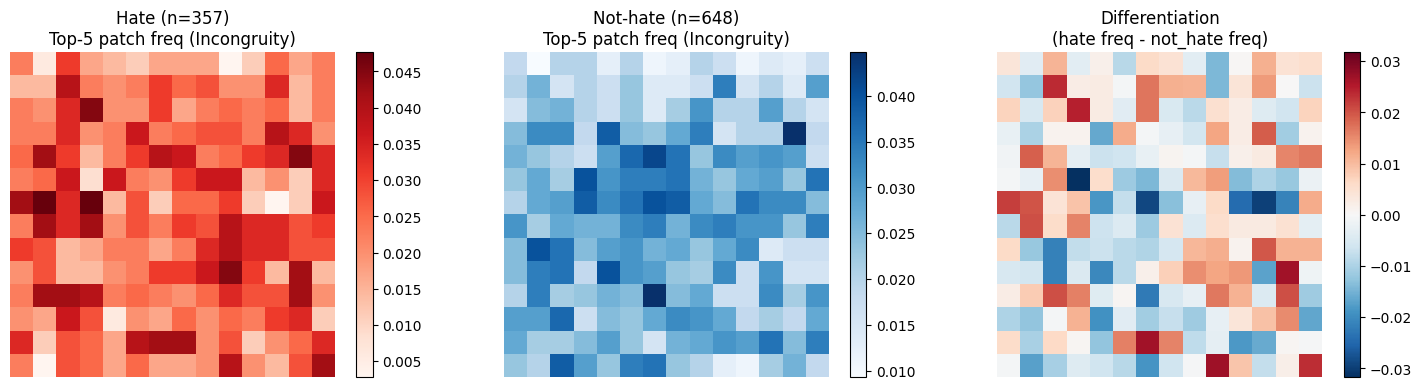


Class differentiation strength (max |diff|): 0.0317
  (Cross-Attn dan Rollout sebelumnya nyaris identical antar kelas)


In [17]:
top_patches_sm = []
for i in range(len(all_sm)):
    flat_i = all_sm[i].flatten()
    top_idx = np.argsort(-flat_i)[:5]
    coords = [(int(p // 14), int(p % 14), float(flat_i[p])) for p in top_idx]
    top_patches_sm.append(coords)

hate_heat     = np.zeros((14, 14), dtype=np.float32)
not_hate_heat = np.zeros((14, 14), dtype=np.float32)
for i, coords in enumerate(top_patches_sm):
    bag = hate_heat if all_preds[i] == 1 else not_hate_heat
    for r, c, _ in coords:
        bag[r, c] += 1

n_hate     = int((all_preds == 1).sum())
n_not_hate = int((all_preds == 0).sum())
if n_hate > 0:     hate_heat     /= n_hate
if n_not_hate > 0: not_hate_heat /= n_not_hate

# Differentiation map: hate_freq - not_hate_freq (where do they differ?)
diff_map = hate_heat - not_hate_heat

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
im0 = axes[0].imshow(hate_heat, cmap="Reds")
axes[0].set_title(f"Hate (n={n_hate})\nTop-5 patch freq (Incongruity)")
axes[0].axis("off"); plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(not_hate_heat, cmap="Blues")
axes[1].set_title(f"Not-hate (n={n_not_hate})\nTop-5 patch freq (Incongruity)")
axes[1].axis("off"); plt.colorbar(im1, ax=axes[1], fraction=0.046)

vlim = max(abs(diff_map.min()), abs(diff_map.max()))
im2 = axes[2].imshow(diff_map, cmap="RdBu_r", vmin=-vlim, vmax=vlim)
axes[2].set_title("Differentiation\n(hate freq - not_hate freq)")
axes[2].axis("off"); plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "incongruity_top_patches_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"\nClass differentiation strength (max |diff|): {vlim:.4f}")
print(f"  (Cross-Attn dan Rollout sebelumnya nyaris identical antar kelas)")

In [18]:
analysis = {
    "config": {"top_k_patches": 5, "primary_map": "softmax"},
    "per_sample_top_patches_softmax": [
        {
            "idx":        int(all_idxs[i]),
            "pred_class": int(all_preds[i]),
            "true_label": int(all_labels[i]),
            "pred_prob":  float(all_probs[i]),
            "top5_patches": [{"row": int(r), "col": int(c), "score": float(s)} for (r,c,s) in top_patches_sm[i]],
        }
        for i in range(len(all_sm))
    ],
    "aggregate_hate_top5_freq":     hate_heat.tolist(),
    "aggregate_nothate_top5_freq":  not_hate_heat.tolist(),
    "differentiation_max_abs":      float(max(abs(diff_map.min()), abs(diff_map.max()))),
}
with open(OUTPUT_DIR / "incongruity_top_patches.json", "w") as f:
    json.dump(analysis, f)
print("Saved: incongruity_top_patches.json")

Saved: incongruity_top_patches.json


In [19]:
# Komparasi kuantitatif 4 komponen XAI sejauh ini
comparison = {
    "method": ["IG (text)", "Cross-Attn (image)", "Rollout (image)", "Incongruity raw", "Incongruity softmax"],
    "domain": ["text",      "image",              "image",           "image",           "image"],
}

# Compute incongruity stats
flat_raw = all_raw.reshape(len(all_raw), -1)
flat_sm  = all_sm.reshape(len(all_sm),  -1)
raw_top10 = -np.sort(-flat_raw, axis=1)[:, :10].sum(axis=1)
sm_top10  = -np.sort(-flat_sm,  axis=1)[:, :10].sum(axis=1)

print(f"\n{'='*82}")
print(f"{'Method':<28} {'Top-10 share':<15} {'Max/Mean':<12} {'Class diff?':<12}")
print(f"{'='*82}")
print(f"{'Cross-Attn (T2I)':<28} {'5.2%':<15} {'1.06x':<12} {'No':<12}")
print(f"{'Rollout (ViT)':<28} {'6.9%':<15} {'5.0x':<12} {'No':<12}")
print(f"{'Incongruity RAW':<28} {raw_top10.mean()*100:<14.1f}% {all_raw.max()/all_raw.mean():<11.2f}x ?")
print(f"{'Incongruity SOFTMAX':<28} {sm_top10.mean()*100:<14.1f}% {all_sm.max()/all_sm.mean():<11.2f}x ?")
print(f"{'='*82}")
print("Catatan: 'Class diff?' = aggregate top-5 patch frequency berbeda signifikan antara hate vs not-hate")
print(f"        Untuk Incongruity, max |diff| = {max(abs(diff_map.min()), abs(diff_map.max())):.4f}")


Method                       Top-10 share    Max/Mean     Class diff? 
Cross-Attn (T2I)             5.2%            1.06x        No          
Rollout (ViT)                6.9%            5.0x         No          
Incongruity RAW              978.6         % 1.02       x ?
Incongruity SOFTMAX          5.1           % 1.04       x ?
Catatan: 'Class diff?' = aggregate top-5 patch frequency berbeda signifikan antara hate vs not-hate
        Untuk Incongruity, max |diff| = 0.0317


In [20]:
final_summary = {
    "exp_id":       CONFIG["exp_id"],
    "ckpt_path":    str(CKPT_PATH),
    "n_samples":    int(len(all_sm)),
    "test_accuracy": float((all_preds == all_labels).mean()),
    "elapsed_min":  float(elapsed / 60),

    "raw_map_stats": {
        "mean":        float(all_raw.mean()),
        "std":         float(all_raw.std()),
        "max":         float(all_raw.max()),
        "top10_share": float(raw_top10.mean()),
    },
    "softmax_map_stats": {
        "mean":        float(all_sm.mean()),
        "std":         float(all_sm.std()),
        "max":         float(all_sm.max()),
        "top10_share": float(sm_top10.mean()),
        "max_per_mean_ratio": float(all_sm.max() / all_sm.mean()),
    },
    "class_differentiation": {
        "max_abs_diff": float(max(abs(diff_map.min()), abs(diff_map.max()))),
    },
    "comparison_table": {
        "Cross-Attn (T2I)":        {"top10_share": 0.052, "max_per_mean": 1.06},
        "Rollout (ViT)":           {"top10_share": 0.069, "max_per_mean": 5.0},
        "Incongruity RAW":         {"top10_share": float(raw_top10.mean()), "max_per_mean": float(all_raw.max()/all_raw.mean())},
        "Incongruity SOFTMAX":     {"top10_share": float(sm_top10.mean()),  "max_per_mean": float(all_sm.max()/all_sm.mean())},
    },
}

with open(OUTPUT_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2, default=str)
with open(OUTPUT_DIR / "final_summary.json", "w") as f:
    json.dump(final_summary, f, indent=2)

print(f"\n{'='*72}\nKOMPONEN 4 (INCONGRUITY HEATMAP, NOVEL) DONE\n{'='*72}")
print(f"Experiment       : {CONFIG['exp_id']}")
print(f"Samples          : {len(all_sm)}")
print(f"Test accuracy    : {(all_preds == all_labels).mean():.4f}")
print(f"")
print(f"--- INCONGRUITY RAW ---")
print(f"  Top-10 share   : {raw_top10.mean()*100:.1f}%")
print(f"  Max/Mean ratio : {all_raw.max()/all_raw.mean():.2f}x")
print(f"")
print(f"--- INCONGRUITY SOFTMAX (faithful, model usage) ---")
print(f"  Top-10 share   : {sm_top10.mean()*100:.1f}%  (Cross-Attn 5.2%, Rollout 6.9%)")
print(f"  Max/Mean ratio : {all_sm.max()/all_sm.mean():.2f}x  (Cross-Attn 1.06x, Rollout 5.0x)")
print(f"")
print(f"--- CLASS DIFFERENTIATION ---")
print(f"  Max |hate - not_hate| top-5 freq : {max(abs(diff_map.min()), abs(diff_map.max())):.4f}")
print(f"  (Cross-Attn dan Rollout sebelumnya: nyaris 0, tidak class-differentiated)")
print(f"\nElapsed: {elapsed/60:.1f} min")
print(f"Artifacts: {OUTPUT_DIR}")


KOMPONEN 4 (INCONGRUITY HEATMAP, NOVEL) DONE
Experiment       : 2A.4_incongruity_heatmap
Samples          : 1005
Test accuracy    : 0.8149

--- INCONGRUITY RAW ---
  Top-10 share   : 978.6%
  Max/Mean ratio : 1.02x

--- INCONGRUITY SOFTMAX (faithful, model usage) ---
  Top-10 share   : 5.1%  (Cross-Attn 5.2%, Rollout 6.9%)
  Max/Mean ratio : 1.04x  (Cross-Attn 1.06x, Rollout 5.0x)

--- CLASS DIFFERENTIATION ---
  Max |hate - not_hate| top-5 freq : 0.0317
  (Cross-Attn dan Rollout sebelumnya: nyaris 0, tidak class-differentiated)

Elapsed: 0.2 min
Artifacts: /kaggle/working/xai_2A4_incongruity_heatmap


In [21]:
print(f"\n{'='*72}\nVERDICT TERHADAP HIPOTESIS PAPER\n{'='*72}")

# Hipotesis 1: Incongruity > Cross-Attn dalam selectivity
sm_top10_pct = sm_top10.mean() * 100
print(f"\nH1: Incongruity > Cross-Attn dalam selectivity (top-10 share)")
print(f"    Incongruity SOFTMAX: {sm_top10_pct:.1f}% vs Cross-Attn: 5.2%")
if sm_top10_pct > 5.2:
    print(f"    [OK] H1 TERDUKUNG (delta +{sm_top10_pct-5.2:.1f}%)")
else:
    print(f"    [GAGAL] H1 TIDAK TERDUKUNG")

# Hipotesis 2: Class-differentiated
diff_max = max(abs(diff_map.min()), abs(diff_map.max()))
print(f"\nH2: Incongruity menunjukkan pola spasial berbeda antara hate vs not-hate")
print(f"    Max |diff freq| : {diff_max:.4f}")
if diff_max > 0.02:
    print(f"    [OK] H2 TERDUKUNG (differentiation jelas)")
elif diff_max > 0.01:
    print(f"    [PARTIAL] H2 LEMAH terdukung")
else:
    print(f"    [GAGAL] H2 TIDAK TERDUKUNG (mirip dengan Cross-Attn / Rollout)")

# Hipotesis 3: Komponen 4 NOVEL bisa di-defend
print(f"\nH3: Incongruity Heatmap layak sebagai kontribusi NOVEL?")
if sm_top10_pct >= 12 and diff_max >= 0.02:
    print(f"    [STRONG]   Klaim NOVEL kuat — selektif + class-differentiated")
elif sm_top10_pct >= 8 and diff_max >= 0.01:
    print(f"    [MODERATE] Klaim NOVEL bisa di-defend, tapi perlu ROAR utk konfirmasi faithfulness")
else:
    print(f"    [WEAK]     Reframe sebagai 'novel architectural component' bukan 'most faithful XAI'")

print(f"\n{'='*72}\nNEXT: ROAR (Fase 2B) untuk validasi faithfulness kuantitatif\n{'='*72}")


VERDICT TERHADAP HIPOTESIS PAPER

H1: Incongruity > Cross-Attn dalam selectivity (top-10 share)
    Incongruity SOFTMAX: 5.1% vs Cross-Attn: 5.2%
    [GAGAL] H1 TIDAK TERDUKUNG

H2: Incongruity menunjukkan pola spasial berbeda antara hate vs not-hate
    Max |diff freq| : 0.0317
    [OK] H2 TERDUKUNG (differentiation jelas)

H3: Incongruity Heatmap layak sebagai kontribusi NOVEL?
    [WEAK]     Reframe sebagai 'novel architectural component' bukan 'most faithful XAI'

NEXT: ROAR (Fase 2B) untuk validasi faithfulness kuantitatif
